## Volumes in 3-D

A value at every point of a 3-D grid (a concentration, a temperature, a density) is hard to see all at once: a `scatter3` of every point is a crowded cloud. MATLAB's two standard views are planes through the volume colored by its values (`slice`), and the surface where it takes one value (`isosurface`). Here the field is two blobs of a concentration, the second one stretched.

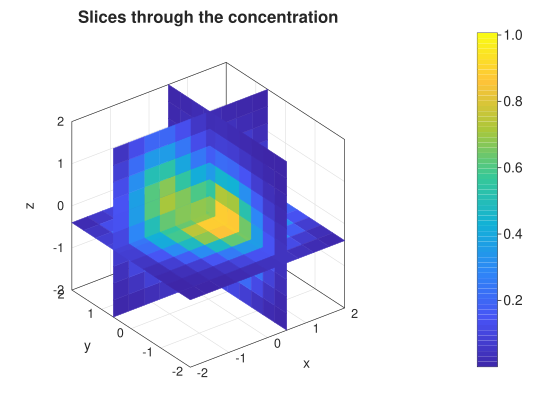

In [ ]:
[x, y, z] = meshgrid(linspace(-2, 2, 11));
V = exp(-((x - 0.5).^2 + y.^2 + (z + 0.3).^2)) + 0.7*exp(-((x + 0.8).^2/0.6 + (y - 0.6).^2 + (z - 0.5).^2/1.5));
slice(x, y, z, V, 0.5, 0.6, -0.4)
shading interp, colorbar
xlabel('x'), ylabel('y'), zlabel('z'), title('Slices through the concentration')

### An isosurface

`isosurface(x, y, z, V, level)` returns the surface where `V` equals the level, as faces and vertices; `patch` draws them. Without a light a surface is one flat color, its shape invisible: `camlight` adds a light from the camera, `lighting gouraud` smooths it across the faces, and `isonormals` takes the normals from the field's gradient so that the shading follows the true surface rather than its triangles.

276 triangles on 140 vertices


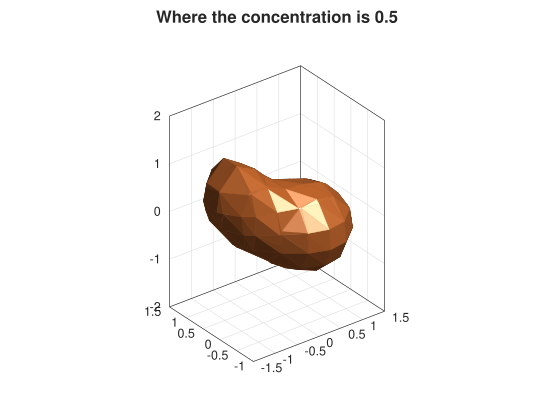

In [ ]:
figure
fv = isosurface(x, y, z, V, 0.5);
fprintf('%d triangles on %d vertices\n', size(fv.faces, 1), size(fv.vertices, 1))
p = patch(fv, 'FaceColor', [0.85 0.45 0.2], 'EdgeColor', 'none');
isonormals(x, y, z, V, p)
view(3), axis equal, grid on
camlight, lighting gouraud
title('Where the concentration is 0.5')

### Colored by another field

A sixth argument gives colors: an array the size of `V`, interpolated at the vertices (`facevertexcdata`). Here the gyroid, a surface that divides space into two interwoven halves, is colored by height.

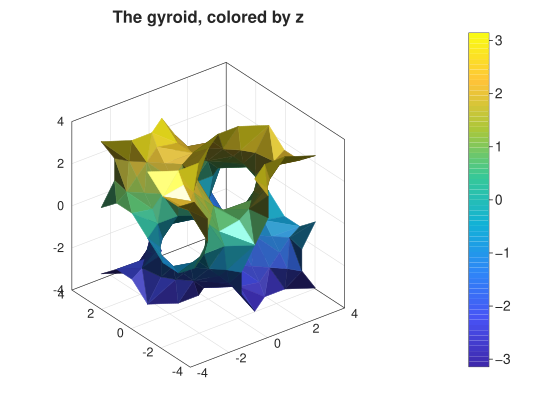

In [ ]:
figure
[x, y, z] = meshgrid(linspace(-pi, pi, 7));
G = sin(x).*cos(y) + sin(y).*cos(z) + sin(z).*cos(x);
p = patch(isosurface(x, y, z, G, 0, z), 'FaceColor', 'interp', 'EdgeColor', 'none');
view(3), axis equal, colorbar
camlight, lighting gouraud
title('The gyroid, colored by z')

### Closing the surface, and contour lines

Where a level surface reaches the edge of the volume it is open, and you see inside it. `isocaps` returns the faces that close it on the volume's boundary, colored by the values there; drawn with the surface, they make a solid. `contourslice` draws contour lines on planes through the volume instead of filling them, which keeps the inside visible.

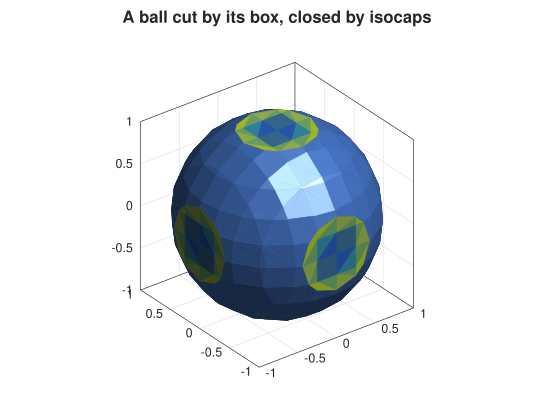

In [ ]:
[x, y, z] = meshgrid(linspace(-1, 1, 9));
V = x.^2 + y.^2 + z.^2;
figure
patch(isosurface(x, y, z, V, 1.2), 'FaceColor', [0.3 0.5 0.85], 'EdgeColor', 'none');
patch(isocaps(x, y, z, V, 1.2, 'below'), 'FaceColor', 'interp', 'EdgeColor', 'none');
view(3), axis equal, camlight, lighting gouraud
title('A ball cut by its box, closed by isocaps')

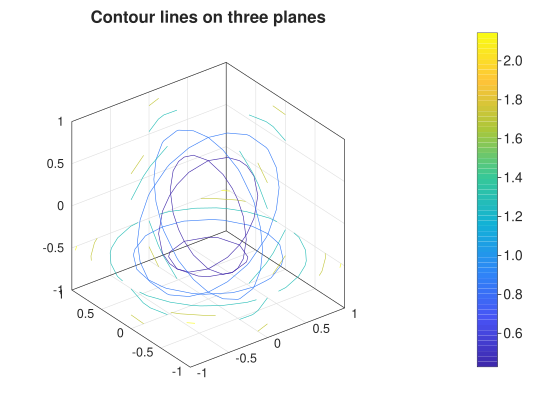

In [ ]:
figure
contourslice(x, y, z, V, 0, 0, -0.5, 6)
view(3), axis equal, grid on, colorbar
title('Contour lines on three planes')